# 08 · Gradients through the network

A fitted NBN is an `nn.Module`.  `log_prob` and `sample` (also with `do=`) are
differentiable, so a network can sit inside a larger PyTorch model: as a
likelihood for parameters upstream of it, as a simulator whose interventions
we optimise, or as a model whose answers we differentiate with respect to its
own parameters.

- **NBN API:** `log_prob(per_node=True)`, `sample(n, do=...)`, `query`,
  `requires_grad_`, `named_parameters` (standard `nn.Module` calls), and the
  mechanisms `MDNMechanism`, `LinearGaussianMechanism`.
- **Runtime:** about 5 s on a laptop CPU.
- **Install:** `pip install "nbn[examples]"`, then `jupyter lab examples/`.
- **Device:** CUDA or Apple MPS when available, else the CPU (set `NBN_EXAMPLES_DEVICE=cpu` to force the CPU).

Ground truth for sections 1 and 2 (a dose and a response):

    Dose     ~ N(0, 1)
    Response = 1.2 Dose + 0.4 sin(2 Dose) + N(0, 0.3^2)

The mean response `f(d) = 1.2 d + 0.4 sin(2 d)` is increasing but not linear.

In [1]:
import math
import os

import matplotlib.pyplot as plt
import numpy as np
import torch

from nbn import LinearGaussianMechanism, MDNMechanism, NeuralBayesianNetwork, seed_all
from nbn.utils.device import resolve_device
from _figures import BLUE, ORANGE, AQUA, VERMILLION, SKY, MAGENTA, YELLOW, GREY, INK, DOUBLE, SINGLE, save, use_style

use_style()  # one style for every example: palette, sizes, fonts (_figures.py)

# "auto" picks CUDA, then Apple MPS, then the CPU.  The stored outputs were made
# with NBN_EXAMPLES_DEVICE=cpu; on an accelerator the last digits can differ.
device = resolve_device(os.environ.get("NBN_EXAMPLES_DEVICE", "auto"))
print("device:", device)



def to_numpy(t: torch.Tensor):
    """Move to the CPU first, then convert: tensors on MPS / CUDA cannot go to numpy directly."""
    return t.detach().cpu().numpy()

device: cpu


## The fitted network

We fit `Dose -> Response` on 4000 lab rows, with an MDN for the response.
Then we freeze it with `requires_grad_(False)`: in sections 1 and 2 the network
is a fixed model, and only the parameters we add around it are trained.

In [2]:
def f(d):
    return 1.2 * d + 0.4 * torch.sin(2 * d)


seed_all(0)
dose = torch.randn(4000, 1)
lab = {"Dose": dose, "Response": f(dose) + 0.3 * torch.randn(4000, 1)}
model = NeuralBayesianNetwork([("Dose", "Response")],
                              {"Dose": ("continuous", 1), "Response": ("continuous", 1)}, device=device)
model.set_mechanism("Response", MDNMechanism(num_components=3))
model.auto_mechanisms()
model.fit(lab, consolidate=False)
model.requires_grad_(False)
print(model)

NeuralBayesianNetwork(nodes=2, edges=1, fitted_mechanisms=2, device=cpu)


## 1. Learn an upstream parameter through `log_prob`

In the field, the dose is not recorded.  We only have a sensor reading `u` for
each patient and the response.  The true dose is a linear calibration of the
reading, `dose = 1.5 u - 0.5`, unknown to us.

We put a learnable `nn.Linear(1, 1)` in front of the network, feed its output
as the `Dose` column of `log_prob`, and maximise the log-likelihood of the
observed responses, `log p(Response | Dose = a u + b)`.  The gradient flows
from the network's log-density back into `a` and `b`.

In [3]:
seed_all(1)
u = torch.rand(500, 1) * 2 - 1
field_response = f(1.5 * u - 0.5) + 0.3 * torch.randn(500, 1)
u, field_response = u.to(device), field_response.to(device)

frozen_before = [p.clone() for p in model.parameters()]
calibration = torch.nn.Linear(1, 1).to(device)
optimizer = torch.optim.Adam(calibration.parameters(), lr=0.05)
losses, a_path, b_path = [], [], []
for step in range(300):
    per_node = model.log_prob({"Dose": calibration(u), "Response": field_response}, per_node=True)
    loss = -per_node["Response"].mean()          # only the response term: a pure likelihood
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    a_path.append(calibration.weight.item())
    b_path.append(calibration.bias.item())

with torch.no_grad():
    true_loss = -model.log_prob({"Dose": 1.5 * u - 0.5, "Response": field_response},
                                per_node=True)["Response"].mean().item()
print(f"learned calibration: a = {a_path[-1]:.3f} (true 1.5), b = {b_path[-1]:.3f} (true -0.5)")
print(f"final loss {losses[-1]:.4f};  loss at the true calibration {true_loss:.4f}")
print("network parameters unchanged by the optimisation:",
      all(torch.equal(p, q) for p, q in zip(model.parameters(), frozen_before)))

learned calibration: a = 1.515 (true 1.5), b = -0.505 (true -0.5)
final loss 0.2185;  loss at the true calibration 0.2187
network parameters unchanged by the optimisation: True


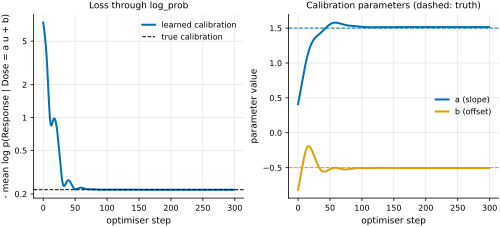

In [4]:
fig, (ax_l, ax_p) = plt.subplots(1, 2, figsize=(DOUBLE, 3.2))
ax_l.plot(losses, color=BLUE, lw=2, label="learned calibration")
ax_l.axhline(true_loss, color=INK, lw=1, ls="--", label="true calibration")
ax_l.set(xlabel="optimiser step", ylabel="- mean log p(Response | Dose = a u + b)",
         title="Loss through log_prob", yscale="log")
ax_l.set_yticks([0.2, 0.5, 1, 2, 5], ["0.2", "0.5", "1", "2", "5"])
ax_l.minorticks_off()
ax_l.legend(frameon=False, fontsize=8)
ax_p.plot(a_path, color=BLUE, lw=2, label="a (slope)")
ax_p.plot(b_path, color=ORANGE, lw=2, label="b (offset)")
ax_p.axhline(1.5, color=BLUE, lw=1, ls="--")
ax_p.axhline(-0.5, color=ORANGE, lw=1, ls="--")
ax_p.set(xlabel="optimiser step", ylabel="parameter value", title="Calibration parameters (dashed: truth)")
ax_p.legend(frameon=False, fontsize=8, loc="center right")
save(fig, "08_fig1")      # vector PDF + 300-dpi PNG in examples/figures/
plt.show()

After about 100 steps the calibration settles at `a = 1.515` and `b = -0.505`
(truth 1.5 and -0.5).  Its loss, 0.2185, is as low as the loss at the true
calibration (0.2187): with 500 noisy rows the data cannot tell the two apart.
Only the calibration moved; the network's parameters are unchanged.

## 2. Optimise an intervention through `sample(n, do=...)`

Which dose gives a mean response of 1.0?  `sample(n, do={"Dose": d})` draws
from the intervened network, and the samples are differentiable with respect
to `d`.  We minimise `(mean of the sampled responses - 1.0)^2` by gradient
descent on `d`, with 2000 fresh samples per step.

The true answer solves `f(d) = 1.0`; we find it with bisection on the true
`f`, for comparison.

In [5]:
TARGET = 1.0
lo, hi = 0.0, 2.0
for _ in range(60):
    mid = (lo + hi) / 2
    lo, hi = (mid, hi) if float(f(torch.tensor(mid))) < TARGET else (lo, mid)
d_true = (lo + hi) / 2

seed_all(2)
d = torch.tensor(0.0, device=device, requires_grad=True)
optimizer = torch.optim.Adam([d], lr=0.05)
do_losses, d_path = [], []
for step in range(150):
    response = model.sample(2000, do={"Dose": d})["Response"]
    loss = (response.mean() - TARGET) ** 2
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    do_losses.append(loss.item())
    d_path.append(d.item())
d_found = float(np.mean(d_path[-30:]))          # average the last steps: the samples are noisy
print(f"dose found by gradient descent: {d_found:.3f}   (mean of the last 30 steps)")
print(f"true dose with f(d) = {TARGET}:      {d_true:.3f}")
with torch.no_grad():
    check = model.sample(20_000, do={"Dose": torch.tensor(d_found, device=device)})["Response"].mean()
print(f"model's mean response at the found dose (20,000 samples): {check.item():.3f}")

dose found by gradient descent: 0.571   (mean of the last 30 steps)
true dose with f(d) = 1.0:      0.540
model's mean response at the found dose (20,000 samples): 1.001


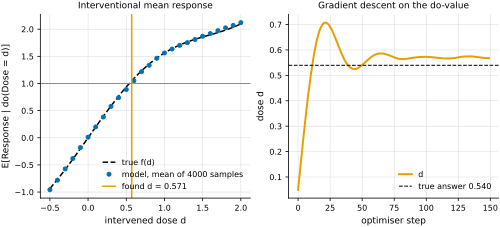

In [6]:
grid = torch.linspace(-0.5, 2.0, 26)
with torch.no_grad():
    model_mean = [model.sample(4000, do={"Dose": torch.tensor(float(g), device=device)})["Response"].mean().item()
                  for g in grid]
fig, (ax_c, ax_d) = plt.subplots(1, 2, figsize=(DOUBLE, 3.2))
ax_c.plot(to_numpy(grid), to_numpy(f(grid)), color=INK, lw=1.5, ls="--", label="true f(d)")
ax_c.plot(to_numpy(grid), model_mean, "o", color=BLUE, ms=4, label="model, mean of 4000 samples")
ax_c.axhline(TARGET, color=GREY, lw=1)
ax_c.axvline(d_found, color=ORANGE, lw=1.5, label=f"found d = {d_found:.3f}")
ax_c.set(xlabel="intervened dose d", ylabel="E[Response | do(Dose = d)]",
         title="Interventional mean response")
ax_c.legend(frameon=False, fontsize=8, loc="lower right")
ax_d.plot(d_path, color=ORANGE, lw=2, label="d")
ax_d.axhline(d_true, color=INK, lw=1, ls="--", label=f"true answer {d_true:.3f}")
ax_d.set(xlabel="optimiser step", ylabel="dose d", title="Gradient descent on the do-value")
ax_d.legend(frameon=False, fontsize=8, loc="lower right")
save(fig, "08_fig2")      # vector PDF + 300-dpi PNG in examples/figures/
plt.show()

Left: the model's interventional mean (dots) follows the true curve `f(d)`.
Right: gradient descent moves `d` from 0 to about 0.57 in about 60 steps; after
that it wobbles a little, because every step uses new samples.  At the found
dose the model's mean response is 1.001, so the optimisation solved the
model's problem.  The true answer is 0.540.  The gap of 0.03 is model error:
near `d = 0.5` the model's mean response is a little below the true `f(d)`
(left plot).

## 3. Sensitivity to a CPD parameter

How much does a downstream answer move when one conditional distribution
changes?  We fit a linear-Gaussian chain `X -> Y -> Z` (ground truth
`X ~ N(1, 1)`, `Y = 2 X + 1 + noise`, `Z = -1.5 Y + 0.5 + noise`, noise
`N(0, 0.5^2)`) and differentiate two quantities with respect to the weight of
`Y` on `X`:

- the mean and the standard deviation of `Z`, estimated from 20,000 samples
  (`sample` is differentiable with respect to the mechanism parameters);
- the log-likelihood of a fresh batch of 1000 rows (`log_prob`).

We check each gradient against a central finite difference.  For the sampled
mean we reseed before each draw, so both sides of the difference use the same
random numbers.  For a linear-Gaussian chain the exact derivatives are also
known: `dE[Z]/dw = w_zy E[X]` and `d sd(Z)/dw = w_zy^2 w sd(X)^2 / sd(Z)`, with
`sd(Z)^2 = w_zy^2 (w^2 sd(X)^2 + sd_Y^2) + sd_Z^2` (`w` is the weight of `Y` on
`X`, `w_zy` the weight of `Z` on `Y`, `sd_Y`, `sd_Z` the noise scales).

In [7]:
seed_all(3)
x = 1.0 + torch.randn(5000, 1)
y = 2 * x + 1 + 0.5 * torch.randn(5000, 1)
z = -1.5 * y + 0.5 + 0.5 * torch.randn(5000, 1)
chain = NeuralBayesianNetwork([("X", "Y"), ("Y", "Z")],
                              dict.fromkeys("XYZ", ("continuous", 1)), device=device)
for node in "XYZ":
    chain.set_mechanism(node, LinearGaussianMechanism())
chain.fit({"X": x, "Y": y, "Z": z})
print("parameters of Y's mechanism:", [name for name, _ in chain.mechanisms["Y"].named_parameters()])
w_yx = dict(chain.mechanisms["Y"].named_parameters())["_weight"]      # the [1, 1] weight of Y on X
w_zy = dict(chain.mechanisms["Z"].named_parameters())["_weight"]
mean_x = dict(chain.mechanisms["X"].named_parameters())["_bias"]
print(f"fitted weights: Y on X {w_yx.item():.4f}, Z on Y {w_zy.item():.4f}; fitted E[X] {mean_x.item():.4f}")

seed_all(4)
fresh = {k: v.to(device) for k, v in zip("XYZ", (x[:1000], y[:1000], z[:1000]))}


def mean_z(seed: int = 5):
    seed_all(seed)
    return chain.sample(20_000)["Z"].mean()


def sd_z(seed: int = 5):
    seed_all(seed)
    return chain.sample(20_000)["Z"].std()


def exact_sd_z(w):
    sd = {k: dict(chain.mechanisms[k].named_parameters())["_log_scale"].exp().item() for k in "XYZ"}
    return np.sqrt(w_zy.item() ** 2 * (w ** 2 * sd["X"] ** 2 + sd["Y"] ** 2) + sd["Z"] ** 2), sd


def heldout_ll():
    return chain.log_prob(fresh).mean()


H = 1e-2
results = {}
for name, fn in (("E[Z] from samples", mean_z), ("sd(Z) from samples", sd_z),
                 ("mean log p(batch)", heldout_ll)):
    value = fn()
    (grad,) = torch.autograd.grad(value, w_yx)
    with torch.no_grad():
        w_yx += H
        up = fn().item()
        w_yx -= 2 * H
        down = fn().item()
        w_yx += H
    results[name] = (value.item(), grad.item(), (up - down) / (2 * H))
    print(f"{name:20s} value {value.item():9.4f}   autograd d/dw {grad.item():9.4f}   "
          f"finite difference {(up - down) / (2 * H):9.4f}")
sd_now, sds = exact_sd_z(w_yx.item())
print(f"exact for the fitted chain: dE[Z]/dw = {(w_zy * mean_x).item():.4f}, "
      f"d sd(Z)/dw = {w_zy.item() ** 2 * w_yx.item() * sds['X'] ** 2 / sd_now:.4f}")

parameters of Y's mechanism: ['_weight', '_bias', '_log_scale']
fitted weights: Y on X 2.0002, Z on Y -1.4970; fitted E[X] 0.9996
E[Z] from samples    value   -3.9548   autograd d/dw   -1.4783   finite difference   -1.4783
sd(Z) from samples   value    3.1355   autograd d/dw    1.4341   finite difference    1.4341
mean log p(batch)    value   -2.8616   autograd d/dw   -0.0387   finite difference   -0.0386
exact for the fitted chain: dE[Z]/dw = -1.4964, d sd(Z)/dw = 1.4463


The plot sweeps the weight of `Y` on `X` around its fitted value, recomputes
the sampled standard deviation of `Z` (same random numbers each time), and
draws the exact curve and the tangent line given by the autograd gradient at
the fitted value.

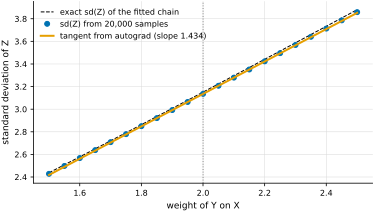

In [8]:
w0 = w_yx.item()
sweep = np.linspace(w0 - 0.5, w0 + 0.5, 21)
values = []
with torch.no_grad():
    for wv in sweep:
        w_yx.fill_(wv)
        values.append(sd_z().item())
    w_yx.fill_(w0)
value0, grad0, _ = results["sd(Z) from samples"]

fig, ax = plt.subplots(figsize=(0.75 * DOUBLE, 3))
fine = np.linspace(sweep[0], sweep[-1], 200)
ax.plot(fine, exact_sd_z(fine)[0], color=INK, lw=1, ls="--", label="exact sd(Z) of the fitted chain")
ax.plot(sweep, values, "o", color=BLUE, ms=5, label="sd(Z) from 20,000 samples")
ax.plot(sweep, value0 + grad0 * (sweep - w0), color=ORANGE, lw=2,
        label=f"tangent from autograd (slope {grad0:.3f})")
ax.axvline(w0, color=GREY, lw=1, ls=":")
ax.set(xlabel="weight of Y on X", ylabel="standard deviation of Z",
       )
ax.legend(frameon=False, fontsize=8)
save(fig, "08_fig3")      # vector PDF + 300-dpi PNG in examples/figures/
plt.show()

**Figure.** Standard deviation of `Z` as one CPD weight is swept: exact for the fitted chain (dashed), estimated from 20,000 samples (dots), and the tangent given by autograd at the fitted weight (orange; dotted vertical line).

Autograd and the finite differences agree to within 1e-4 for all three
quantities (for example -1.4783 for `E[Z]`).  The gradients from samples are
within 0.02 of the exact ones of the fitted chain (-1.4783 against -1.4964 for
`E[Z]`, 1.4341 against 1.4463 for `sd(Z)`); that difference is the Monte-Carlo
error of 20,000 samples.  In the plot the tangent stays close to the sampled
values over the whole range, because `sd(Z)` is nearly linear in this weight
here.

## 4. What is not differentiable: `query`

`query` and `query_batch` are built for speed: variable elimination detaches
its factors and likelihood weighting runs without a graph.  Their outputs never
carry gradients, even when the network's parameters require them.  To
differentiate an interventional quantity, use `sample(n, do=...)` as in
section 2; to differentiate a likelihood, use `log_prob`.

In [9]:
chain.requires_grad_(True)
weights, particles = chain.query(["Z"], evidence={"X": 1.0}, n_samples=1000)
print("query(['Z'], evidence={'X': 1.0}) -> weights.requires_grad =", weights.requires_grad,
      "| particles.requires_grad =", particles.requires_grad)
print("sample(1000)['Z'].requires_grad =", chain.sample(1000)["Z"].requires_grad)
print("log_prob(rows).requires_grad    =", chain.log_prob(fresh).requires_grad)

query(['Z'], evidence={'X': 1.0}) -> weights.requires_grad = False | particles.requires_grad = False
sample(1000)['Z'].requires_grad = True
log_prob(rows).requires_grad    = True
